#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [48]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [49]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

answer:  We convert the image to grayscale because each pixel is represented by a single intensity value, allowing us to apply SVD directly to a two-dimensional matrix. For RGB images, we would need to decompose the three color channels separately.

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [50]:
img = Image.open('/content/drive/MyDrive/urban.jpg')
imggray = img.convert('L')

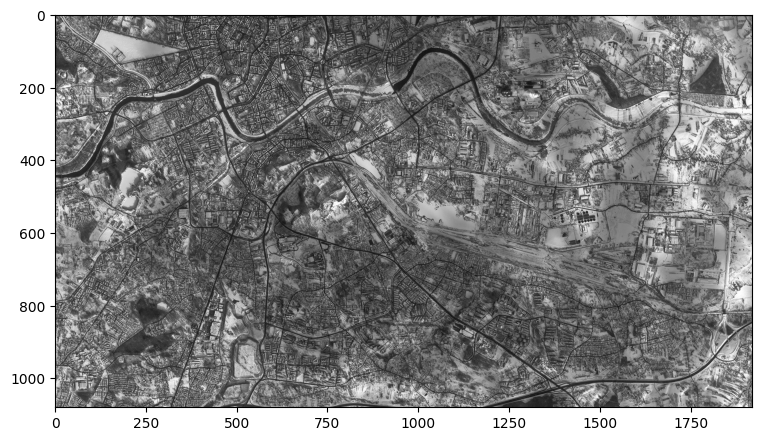

In [51]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

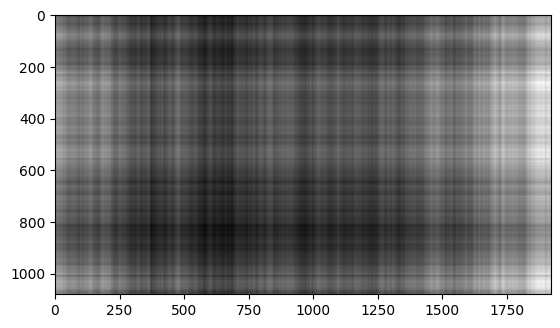

In [52]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

1. The image becomes clearer as more SVD components are used. The first components contain most of the image energy.
2. Around 50–100 components can give a decent reconstruction, depending on the image.
3. The image loses most of its main structure and becomes difficult to recognize/ darker, although some details remain visible.

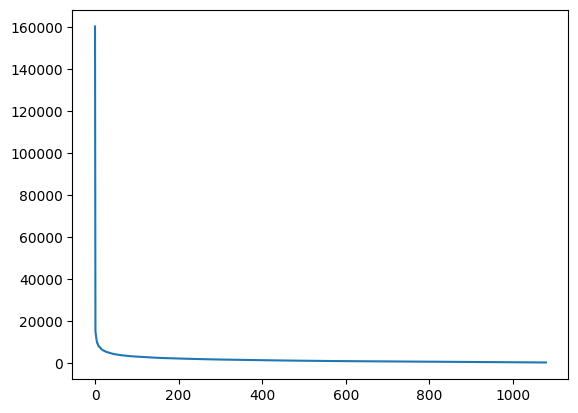

In [53]:
U.shape
sigma.shape
plt.plot(sigma)

In [54]:
# Percentage of retained SVD energy

energy = np.cumsum(sigma**2) / np.sum(sigma**2) * 100

for k in [1, 5, 10, 20, 50, 100, 200]:
    print(f"k = {k}: {energy[k-1]:.2f}%")

k = 1: 86.20%
k = 5: 88.41%
k = 10: 89.68%
k = 20: 91.23%
k = 50: 93.56%
k = 100: 95.47%
k = 200: 97.40%


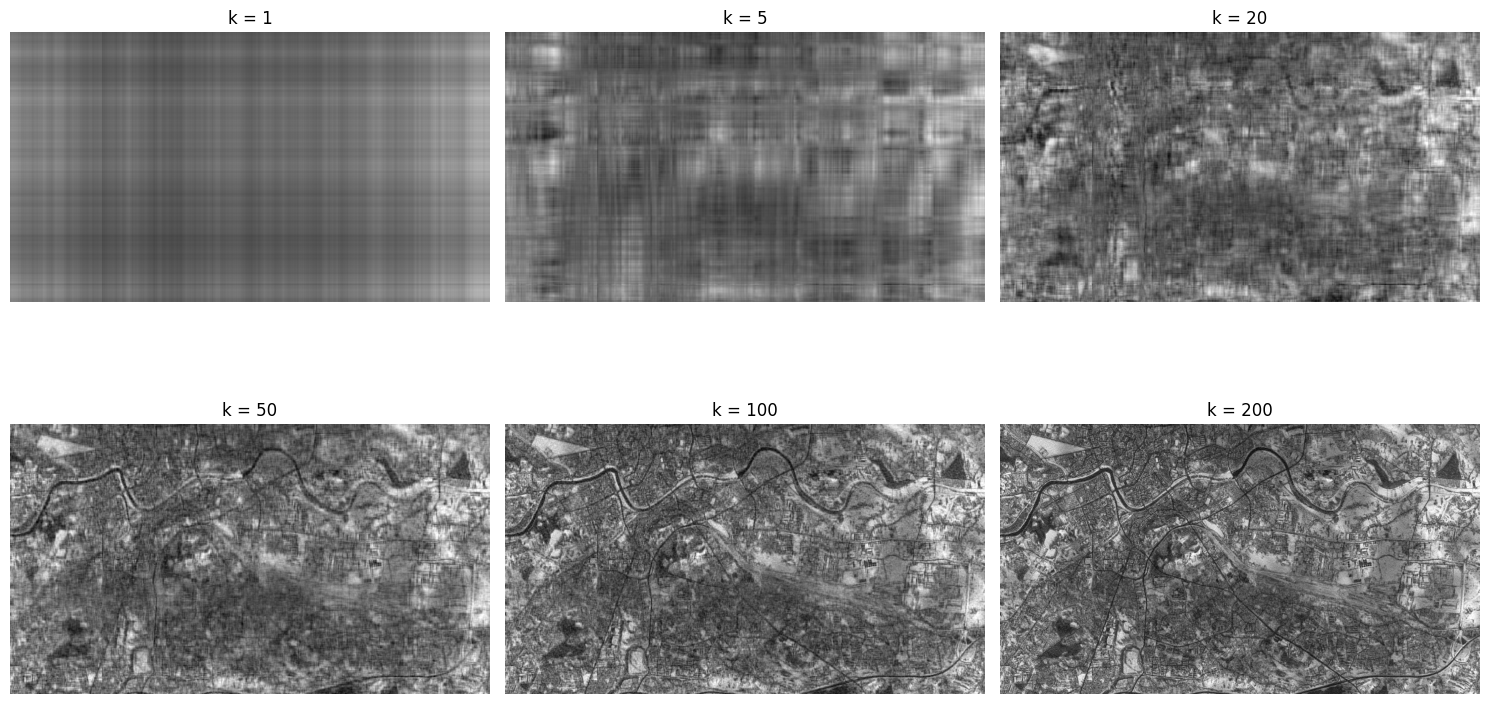

In [55]:
k_values = [1, 5, 20, 50, 100, 200]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, k in zip(axes.flat, k_values):
    reconstructed = (
        U[:, :k] @ np.diag(sigma[:k]) @ V[:k, :]
    )

    ax.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'k = {k}')
    ax.axis('off')

plt.tight_layout()
plt.show()

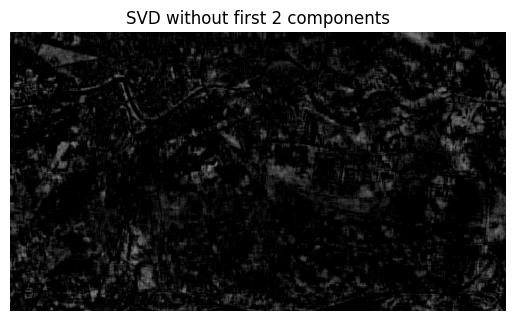

In [56]:
k = 50

reconstructed = (
    U[:, 2:k] @ np.diag(sigma[2:k]) @ V[2:k, :]
)

plt.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)
plt.title("SVD without first 2 components")
plt.axis('off')
plt.show()

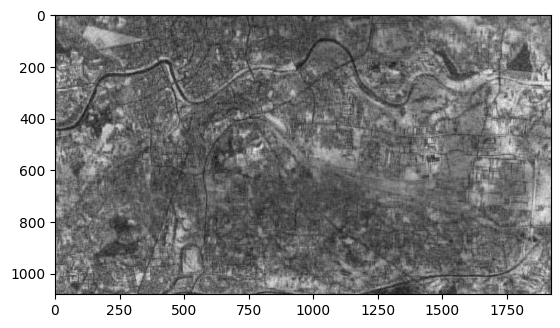

In [57]:
i = 70
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


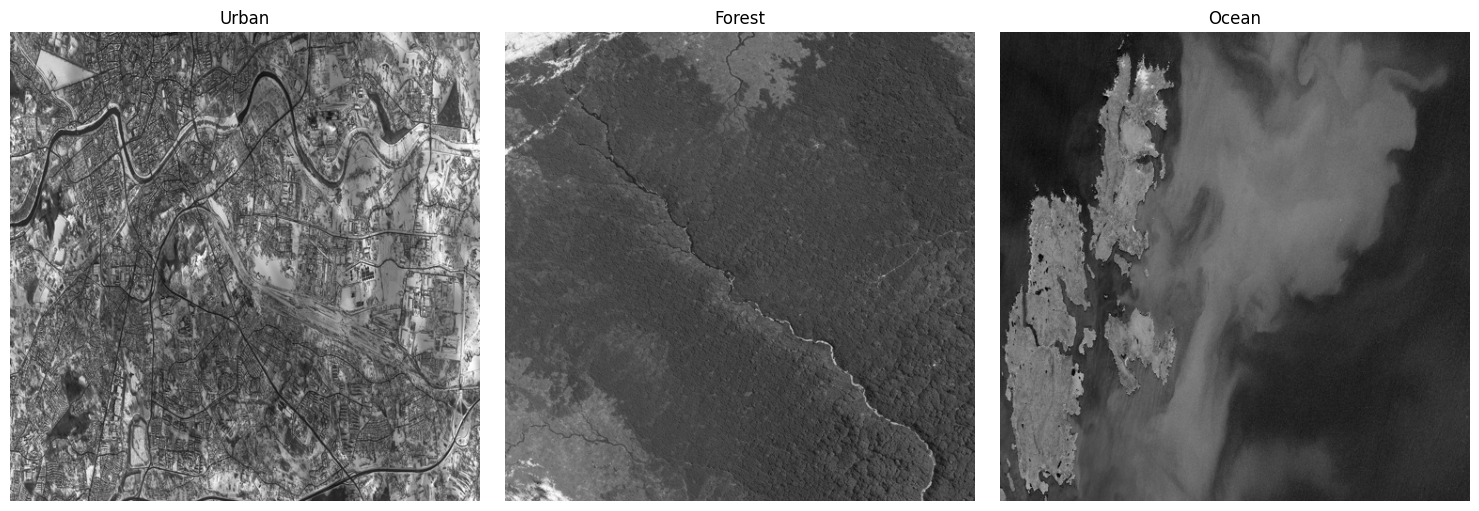

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

drive.mount('/content/drive')

base_path = '/content/drive/MyDrive/'

image_files = {
    'Urban': 'urban.jpg',
    'Forest': 'forest.jpg',
    'Ocean': 'ocean.jpg'
}

images = {}

for name, filename in image_files.items():
    img = Image.open(base_path + filename).convert('L')
    img = img.resize((500, 500))
    images[name] = np.asarray(img, dtype=np.float64)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')

plt.tight_layout()
plt.show()

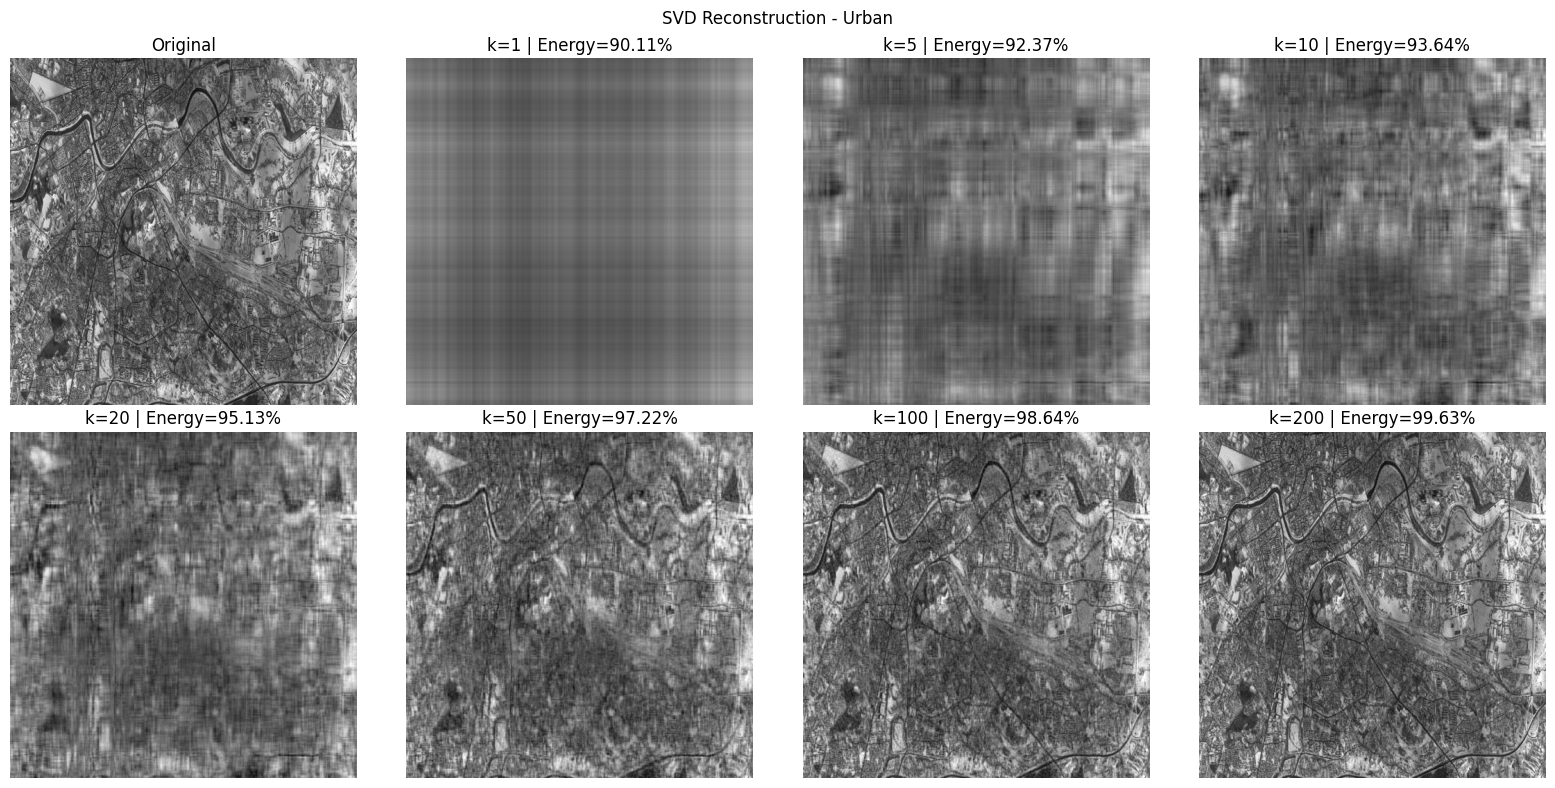

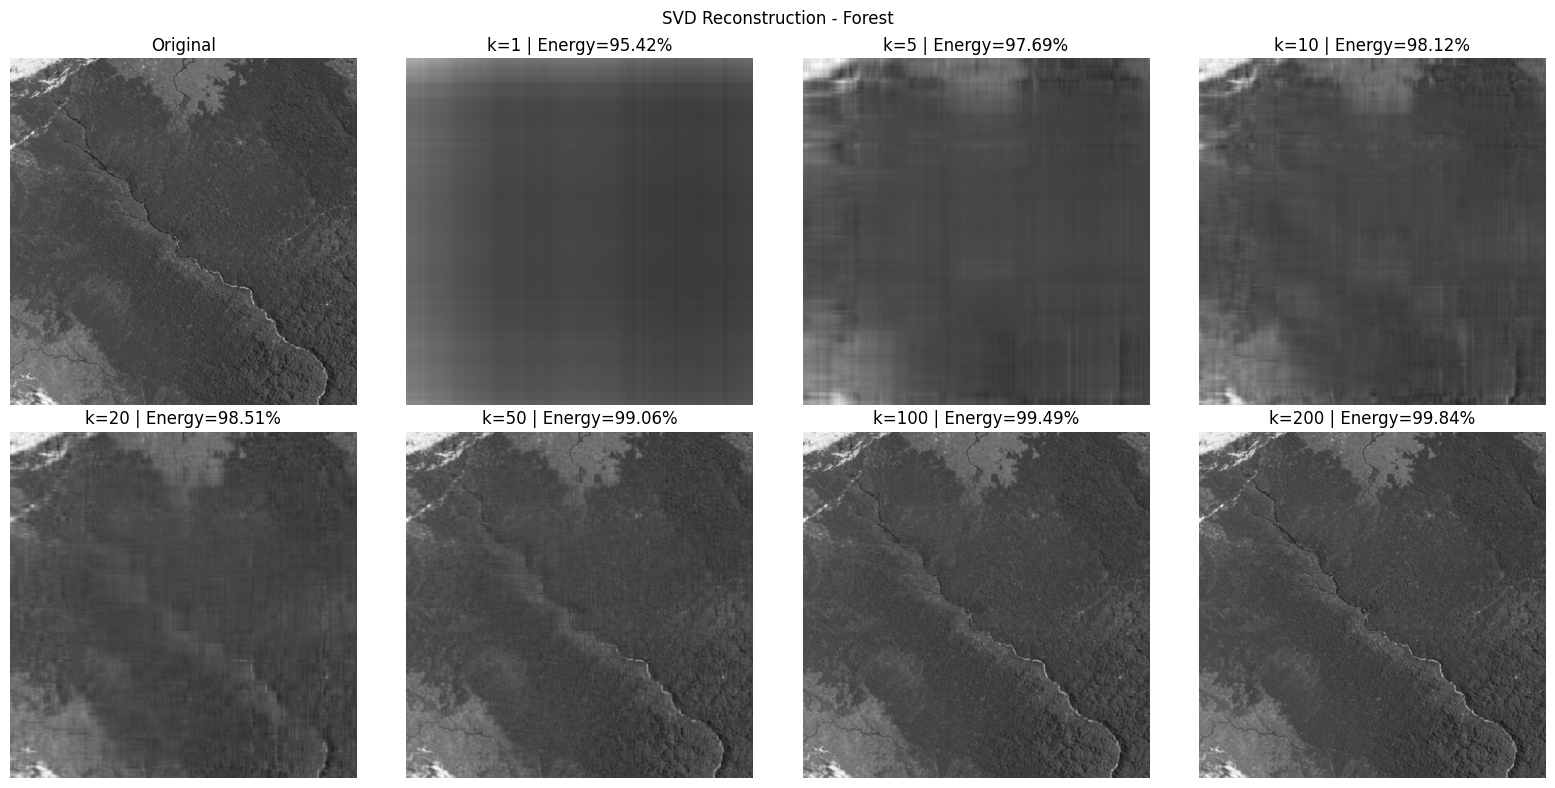

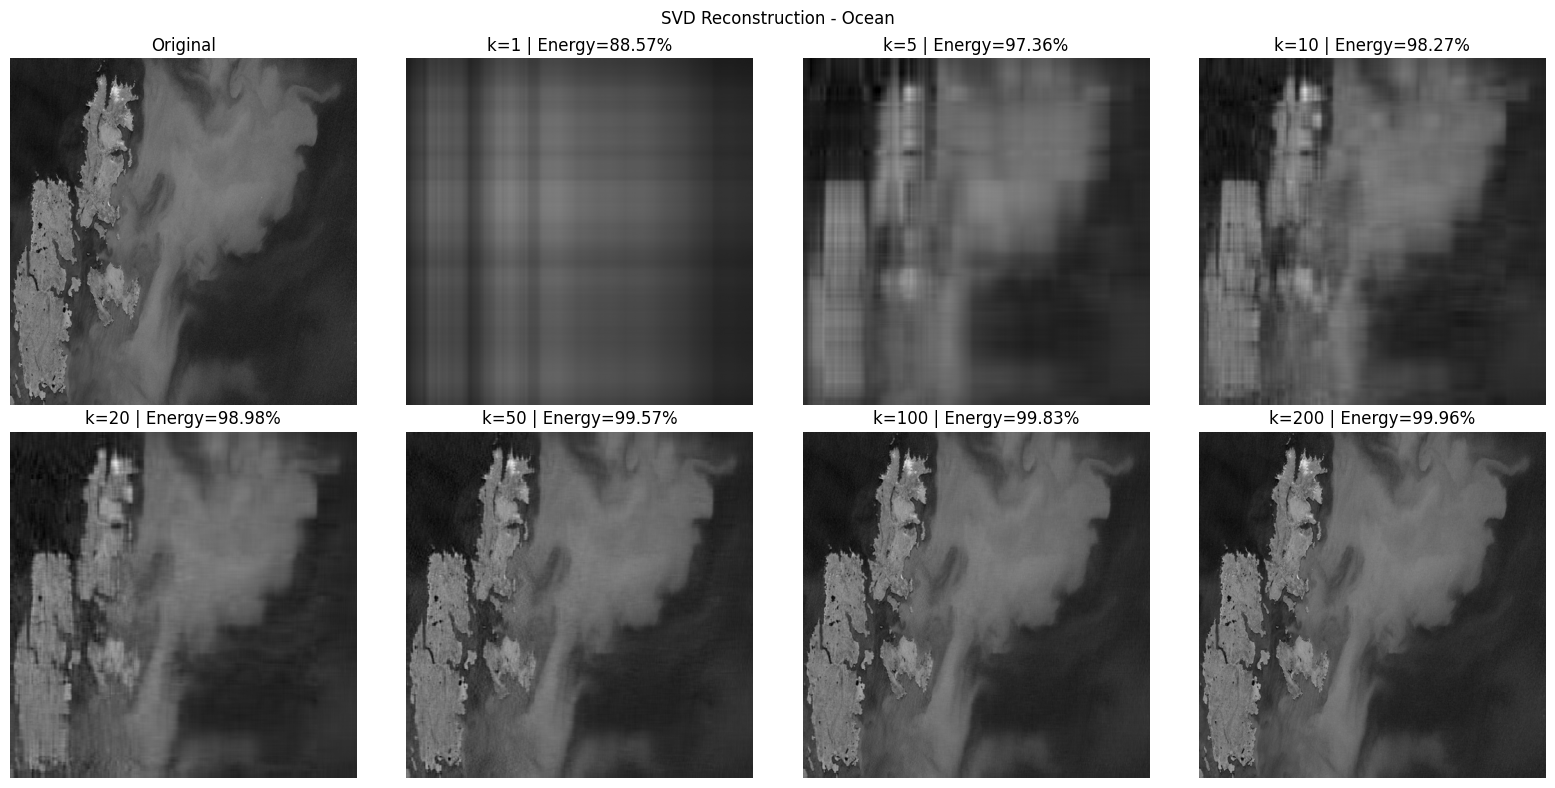

In [60]:
k_values = [1, 5, 10, 20, 50, 100, 200]

svd_results = {}

for name, img in images.items():

    U, sigma, V = np.linalg.svd(img, full_matrices=False)
    svd_results[name] = (U, sigma, V)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0, 0].set_title('Original')

    energy = np.cumsum(sigma**2) / np.sum(sigma**2) * 100

    for ax, k in zip(axes.flat[1:], k_values):
        reconstructed = (U[:, :k] * sigma[:k]) @ V[:k, :]

        ax.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'k={k} | Energy={energy[k-1]:.2f}%')

    for ax in axes.flat:
        ax.axis('off')

    plt.suptitle(f'SVD Reconstruction - {name}')
    plt.tight_layout()
    plt.show()

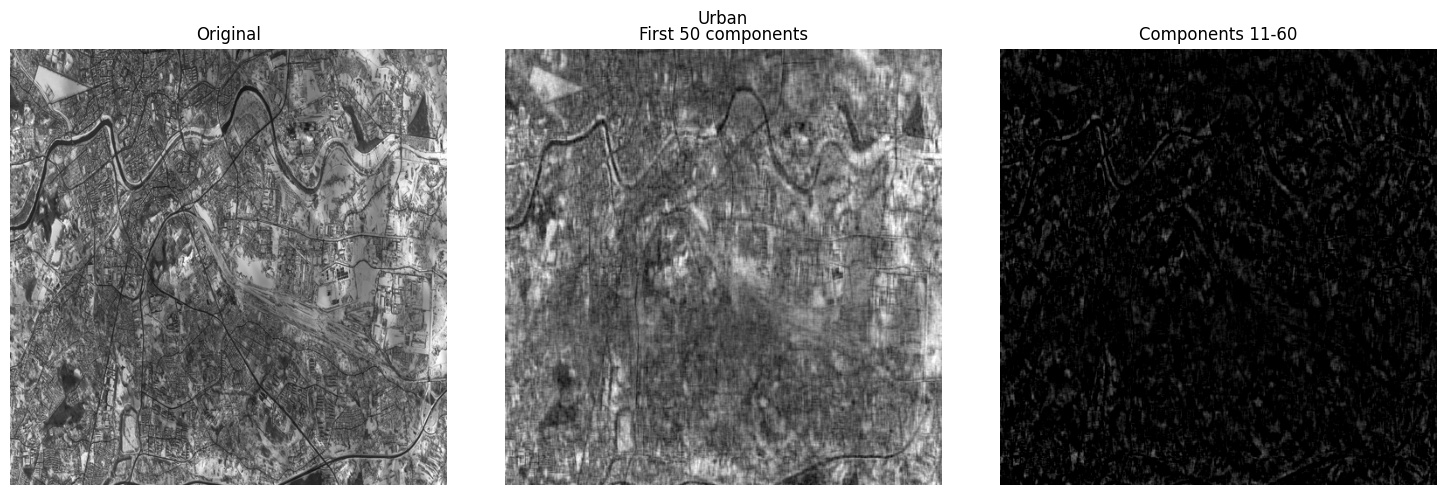

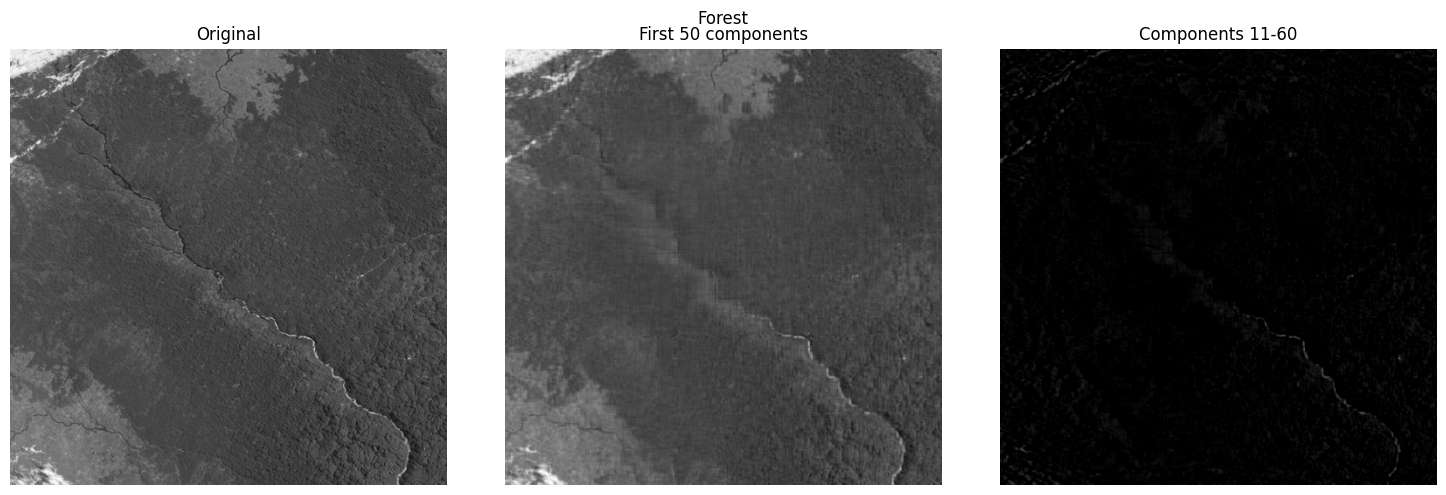

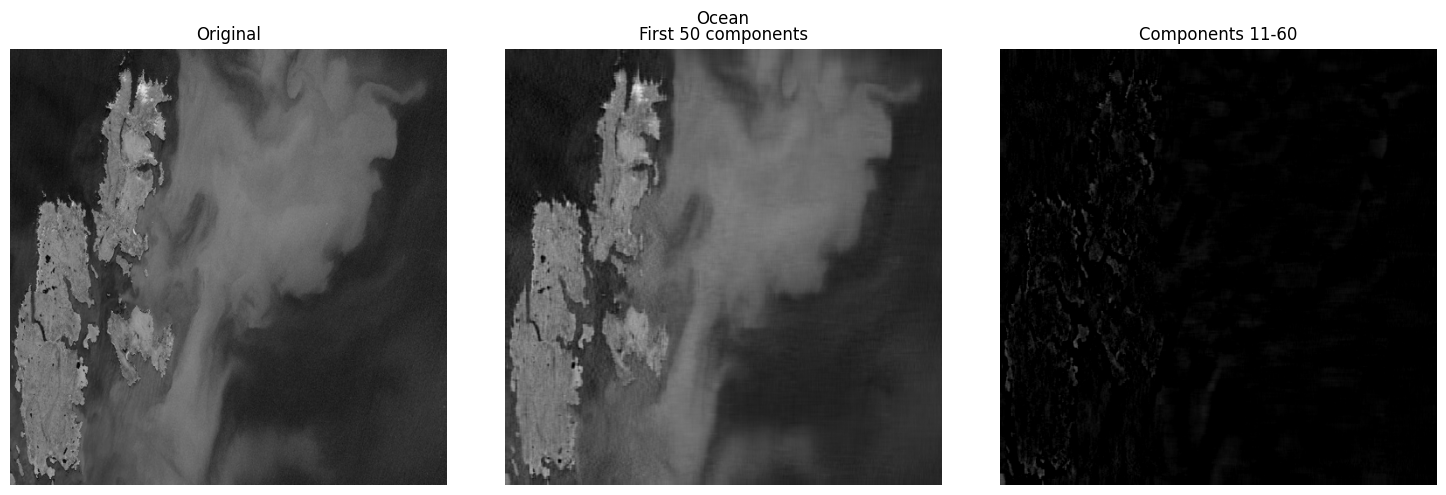

In [59]:
k = 50
skip = 10

for name, img in images.items():

    U, sigma, V = svd_results[name]

    standard = (U[:, :k] * sigma[:k]) @ V[:k, :]

    shifted = (
        U[:, skip:skip+k] * sigma[skip:skip+k]
    ) @ V[skip:skip+k, :]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, image, title in zip(
        axes,
        [img, standard, shifted],
        ['Original', 'First 50 components', 'Components 11-60']
    ):
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

Urban: 124 components for 99% retained energy
Forest: 46 components for 99% retained energy
Ocean: 21 components for 99% retained energy


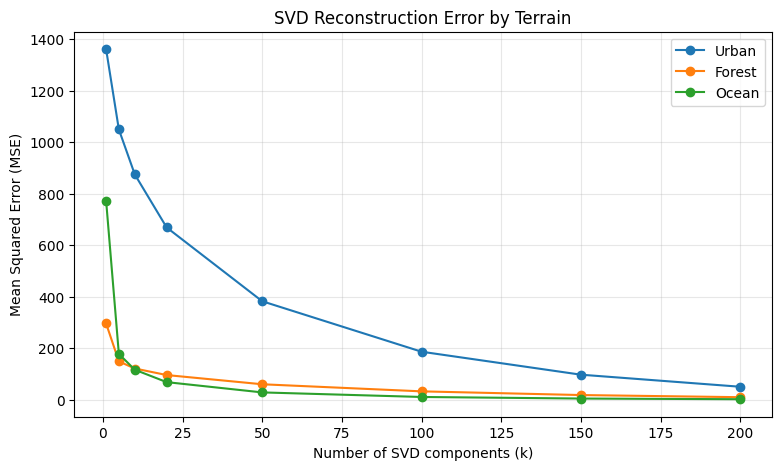

In [61]:
k_values = [1, 5, 10, 20, 50, 100, 150, 200]

plt.figure(figsize=(9, 5))

for name, img in images.items():

    U, sigma, V = svd_results[name]
    mse_values = []

    for k in k_values:
        reconstructed = (U[:, :k] * sigma[:k]) @ V[:k, :]
        mse = np.mean((img - reconstructed)**2)
        mse_values.append(mse)

    plt.plot(k_values, mse_values, marker='o', label=name)

    energy = np.cumsum(sigma**2) / np.sum(sigma**2)
    k_99 = np.searchsorted(energy, 0.99) + 1

    print(f'{name}: {k_99} components for 99% retained energy')

plt.xlabel('Number of SVD components (k)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('SVD Reconstruction Error by Terrain')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Task 1 – SVD Reconstruction

The image quality improves when more SVD components are used. Around 50–100 components give a decent reconstruction, depending on the image.

### Task 2 – Skipping the First 10 Components

The images are much worse when we skip the first 10 components. They are almost impossible to recognize because we lose important information.

### Task 3 – Different Terrains

I noticed that different terrains need different numbers of components.

- **Urban:** Around 200 components are needed because the image has many small details.
- **Forest:** Around 100 components give a good result.
- **Ocean:** Around 50–100 components are enough.

The urban image has the highest reconstruction error, while the forest and ocean images are easier to reconstruct.